# PaDiM
Method from the literature (Defard et al., 2021).
No training: a frozen ImageNet-pretrained backbone extracts patch features (layer1 + layer2 + layer3, 100 channels
chosen at random) from the normal training images, and a multivariate Gaussian is fitted at each patch position.
At test time the anomaly map is the Mahalanobis distance of each patch from its Gaussian (smoothed with sigma 4);
the image score is the maximum of the map.

Same protocol as the custom model: same split (fit on `train/`), 256x256 without center crop, same `evaluate`.
Model from anomalib (`PadimModel`), wrapped in `models/literature_models.py`.
Backbone `resnet18.tv_in1k`: the torchvision weights, the same as the teacher of the custom model.
The main image score is the native one (`image_auroc`); `image_auroc_top1pct` uses the top-1% score of the custom model.

In [5]:
from run_literature import run_literature_single_class, fit_literature_model
from utils.visualization import visualize_anomalies
from utils.helpers import get_device
from pathlib import Path
import pandas as pd
from warnings import filterwarnings
filterwarnings("ignore")

In [2]:
config = {

    'experiment_name': 'resnet18',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,

    # dataset
    'img_size': (256, 256),
    'batch_size': 32,

    # model (default values of the paper / anomalib)
    'model_name': 'PaDiM',
    'backbone_name': 'resnet18.tv_in1k',
    'feature_layers': ['layer1', 'layer2', 'layer3'],
    'n_features': 100,
    'output_dir': './experiments/padim',
}

DEVICE = get_device(config['device'])

In [3]:
classes_to_run = ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']
all_results = {}

for cls in classes_to_run:
    all_results[cls] = run_literature_single_class(cls, config)

df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

results_csv = Path(config['output_dir']) / config['experiment_name'] / "overall_results.csv"
df_results.to_csv(results_csv)

display(df_results.round(4))


==============================  Starting class: BOTTLE  ==============================
Random seed set to 42.


Evaluating: 100%|██████████| 3/3 [00:02<00:00,  1.14it/s]



==============================  Starting class: CABLE  ==============================
Random seed set to 42.


Evaluating: 100%|██████████| 5/5 [00:07<00:00,  1.52s/it]



==============================  Starting class: CAPSULE  ==============================
Random seed set to 42.


Evaluating: 100%|██████████| 5/5 [00:07<00:00,  1.53s/it]


... (21 outputs left out)

Evaluating: 100%|██████████| 3/3 [00:03<00:00,  1.16s/it]



==============================  Starting class: ZIPPER  ==============================
Random seed set to 42.


Evaluating: 100%|██████████| 5/5 [00:03<00:00,  1.57it/s]


,image_auroc,pixel_auroc,aupro,image_auroc_top1pct
bottle,0.9742,0.9817,0.9501,0.9976
cable,0.7708,0.9593,0.8992,0.8570
capsule,0.8377,0.9825,0.9111,0.9021
carpet,0.9860,0.9906,0.9656,0.9888
grid,0.9052,0.9525,0.8892,0.9148
hazelnut,0.7600,0.9785,0.9389,0.9513
leather,1.0000,0.9930,0.9840,1.0000
metal_nut,0.9511,0.9736,0.9305,0.9809
pill,0.8567,0.9496,0.9369,0.9291
screw,0.7201,0.9769,0.9152,0.6810


Random seed set to 42.


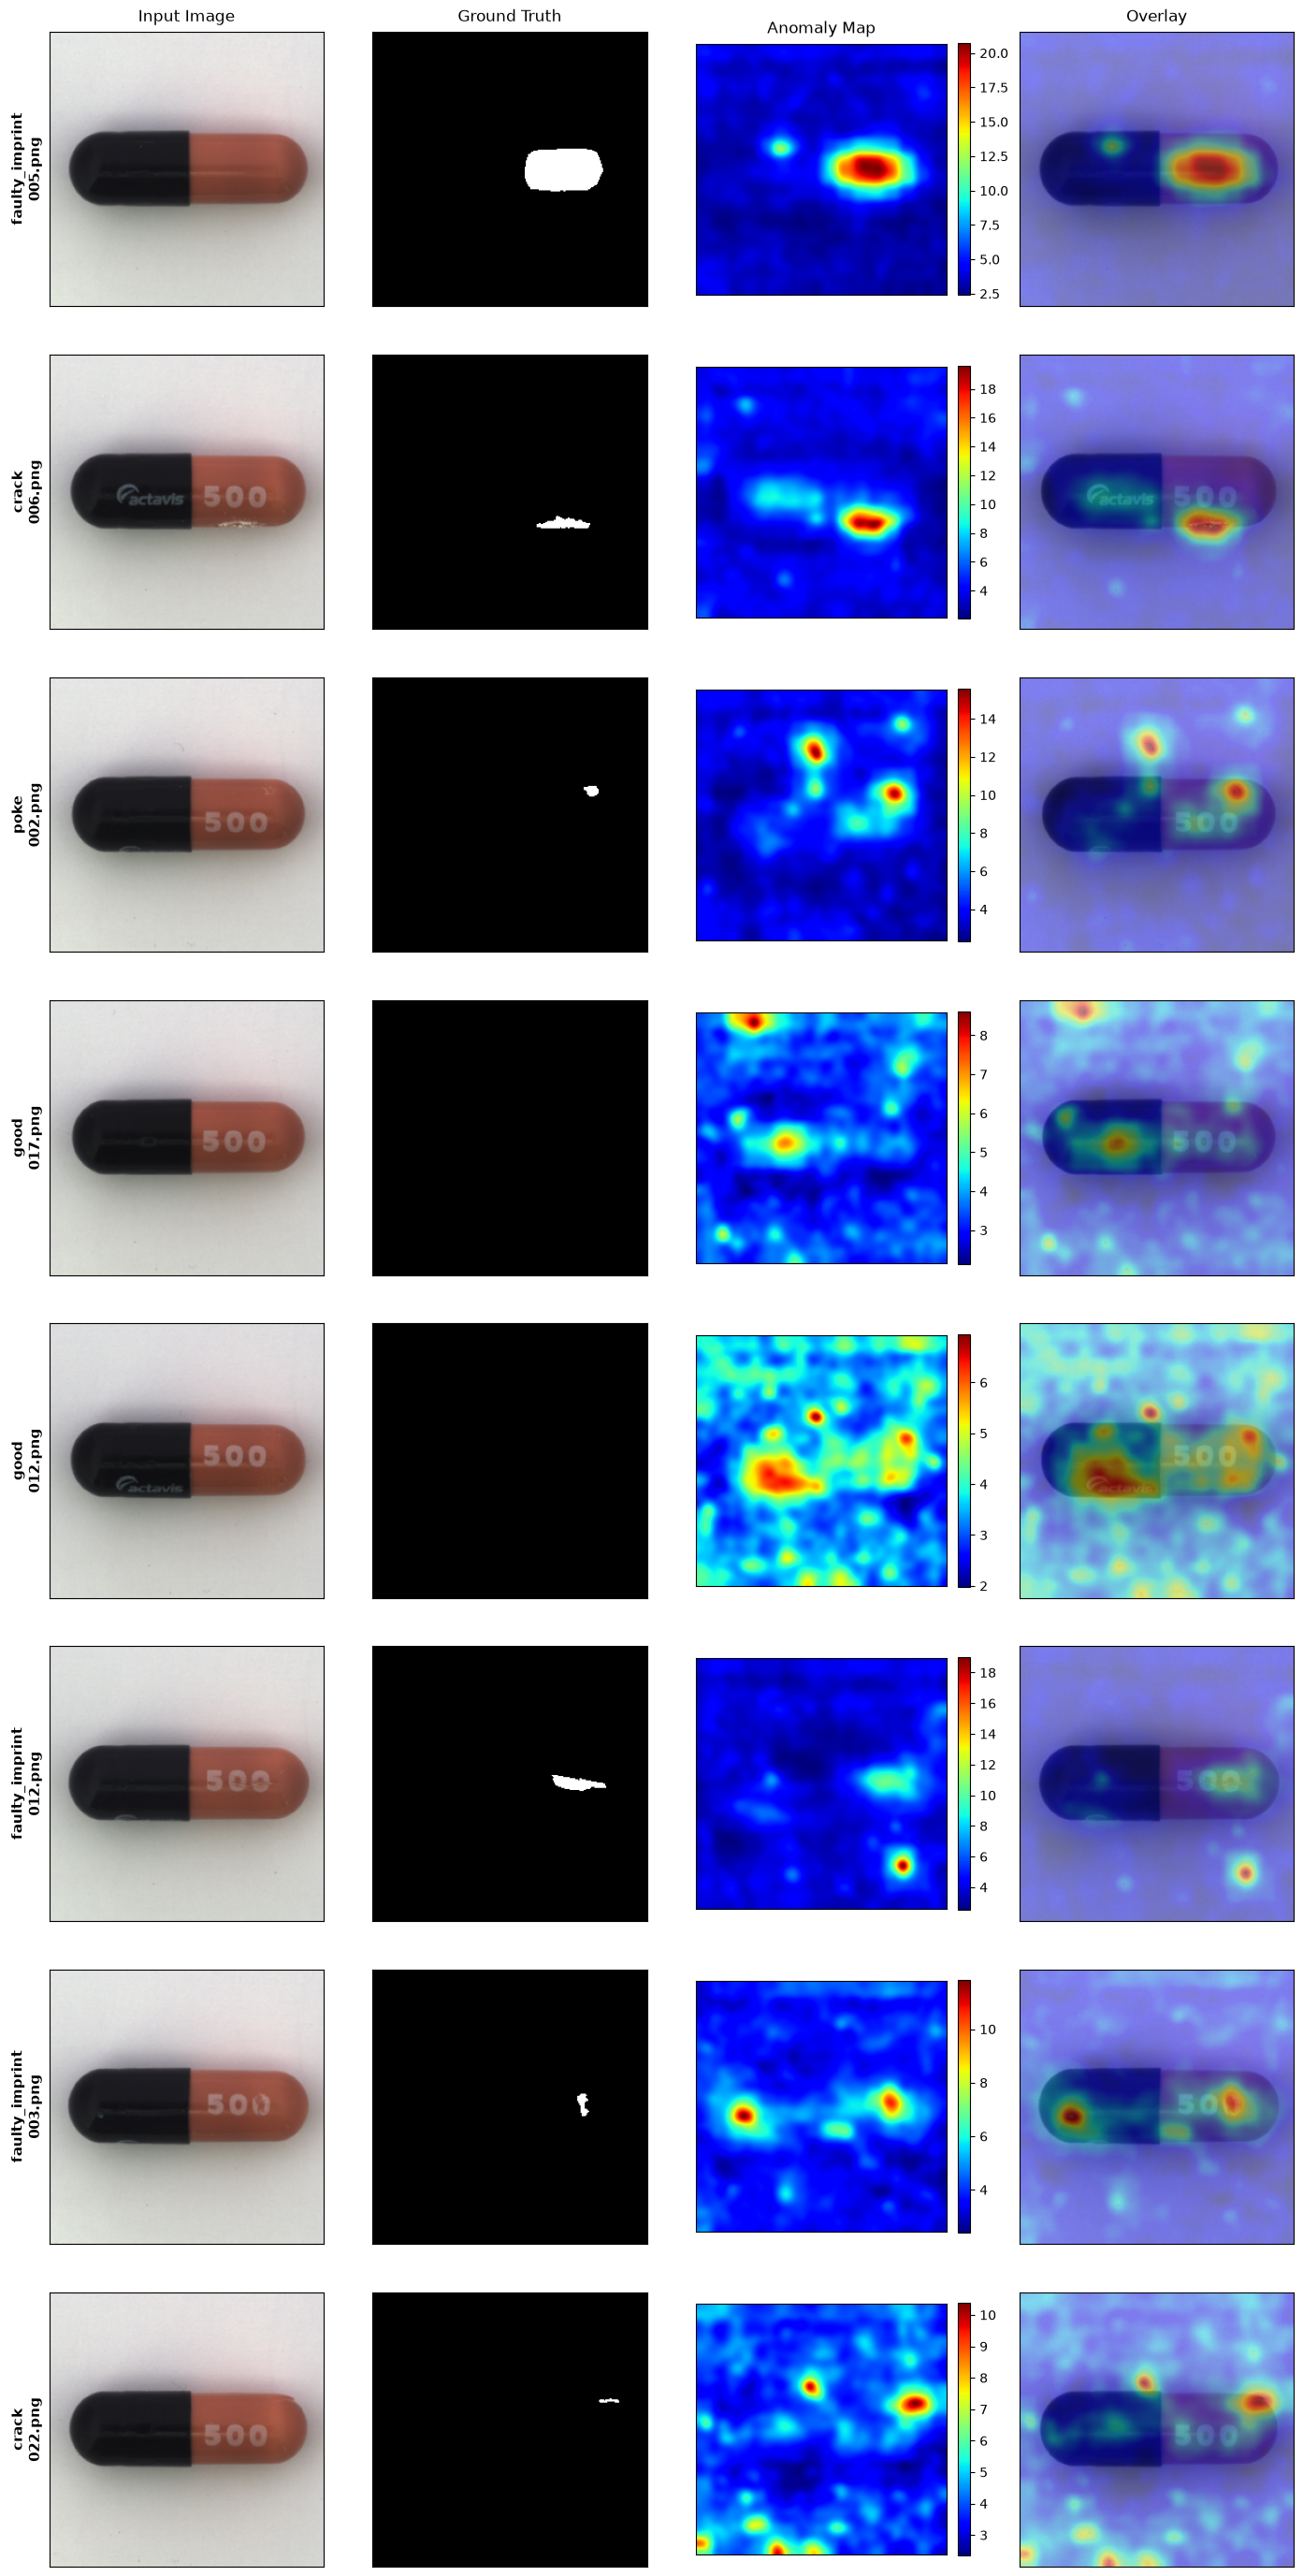

In [4]:
object_name = "capsule"  # Change this to the desired object name

model, test_loader = fit_literature_model(object_name, config)  # same seed as the run: same model
visualize_anomalies(model, test_loader, DEVICE)